### Phase 3 — Interroger l'API VIES (J2 matin)

Commencez par trois appels **à la main** : un numéro que vous savez bon, un dont la clé est fausse, un que vous avez inventé de toutes pièces. **Lisez les réponses en entier** avant d'écrire la moindre boucle. Le service ne se contente pas de dire oui ou non : regardez tous les champs qu'il renvoie et demandez-vous ce que chacun signifie.

Sollicitez-le ensuite plus sérieusement, sur quelques dizaines de numéros d'affilée, et **regardez tout ce qu'il vous répond**, pas seulement le cas passant. Confrontez chaque réponse à ce que vous savez du numéro envoyé. Si l'une d'elles vous paraît contredire ce que vous attendiez, ne la contournez pas : c'est probablement là que se joue le brief.

Écrivez alors votre **script de collecte** :

- un **mode échantillon** paramétrable dès le départ (deux cents numéros suffisent à tout démontrer et coûtent quelques minutes) ;
- une **temporisation** entre les appels ;
- un **fichier de résultats** qui conserve, pour chaque numéro, la réponse obtenue **et sa date** ;
- une relance qui **ne refait pas** les appels déjà faits ;
- un **journal** qui permet de savoir après coup ce qui s'est passé pendant la collecte : début et fin de campagne, chaque appel avec son code HTTP et son temps de réponse, chaque erreur du service, chaque numéro sauté parce qu'il avait déjà été vérifié. Utilisez le module `logging` de Python plutôt que des `print()` (voir [Ressources](#ressources)).

Questions à vous poser : votre échantillon de deux cents numéros représente-t-il le référentiel ? Comment l'avez-vous tiré ? Une fois une réponse obtenue, combien de temps reste-t-elle vraie : un numéro vérifié il y a six mois doit-il être revérifié avant la prochaine facture ?


In [1]:
import sys
import pandas as pd

from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
df = pd.read_csv("../data/tva_propre.csv", dtype=str, keep_default_na=False)

df.head()

,id,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,tva_normalise,est_valide,motif,tva_sans_pays
0,2,Solaris Technologies SARL,PT,PT787327239,2024-03-29,reprise_erp,PT787327239,True,ok,787327239
1,3,Verso Consulting NV,LU,LU71043234,2024-02-16,crm,LU71043234,True,ok,71043234
2,4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur,SE751298146001,True,ok,751298146001
3,6,Kappa Logistics AB,DK,DK61530843,2025-01-14,import_fournisseur,DK61530843,True,ok,61530843
4,8,Vertex Industries SARL,SE,SE.314125231601,2025-03-31,reprise_erp,SE314125231601,True,ok,314125231601


In [6]:


# je créé un échantillon 
echantillon = df.sample(n=200, random_state=12)

#random_state = seed

echantillon.head()

,id,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,tva_normalise,est_valide,motif,tva_sans_pays
4267,7395,Alpine Transports GmbH,LU,LU84999040,2024-10-28,reprise_erp,LU84999040,True,ok,84999040
2426,4137,Meridian Services SAS,LU,LU.84881522,2024-09-28,crm,LU84881522,True,ok,84881522
3272,5621,Nord Distribution SARL,BE,BE1536372310,2024-05-19,crm,BE1536372310,True,ok,1536372310
3929,6793,Orion Distribution SAS,FR,FR62821216405,2024-12-27,portail_client,FR62821216405,True,ok,62821216405
4953,8549,Textil Trading Lda,NL,NL316959893B23,2024-05-13,reprise_erp,NL316959893B23,True,ok,316959893B23


In [10]:
# J'initialise mon fichier de résultat
# j'applique successivement :
#  - l'ajout d'un fichier de résultat (fichier de sortie), je convertis la réponse JSON pour qu'elle soit facilement traitable derière, plutot que importer le texte brut, 
#  - une relance qui ne refait pas les numéros d'appel déjà faits (requetes_deja_faites), 
#  - un journal de log "requetes_api.log"

import csv
import time
from datetime import datetime
import requests 
import os
import logging 


logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)s %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S", 
    filename="requetes_api.log",
    encoding="utf-8",
    )

fichier_sortie = "resultats_requetes.csv"
url_api = "https://ec.europa.eu/taxation_customs/vies/rest-api/ms"


def sauvegarder_resultat(requete, reponse, temps_reponse):
  date_actuelle = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
  with open(fichier_sortie, mode="a", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([date_actuelle, requete, reponse, temps_reponse])

def main() -> None: 
  logging.info("Démarrage du script de vérification API")
  requetes_deja_faites = set()
  if not  os.path.exists(fichier_sortie):
    with open(fichier_sortie, mode="w", newline="", encoding="utf-8") as f:
      writer = csv.writer(f)
      writer.writerow(["date", "requete", "reponse", "temps_reponse"])
    logging.info(f"Création du fichier de sortie : {fichier_sortie}")
  else:
    with open(fichier_sortie, mode="r", newline="", encoding="utf-8") as f:
      reader = csv.DictReader(f)
      for ligne in reader:
        requetes_deja_faites.add(ligne["requete"])
    logging.info(
      f"Reprise : {len(requetes_deja_faites)} requêtes déjà effectuées"
      "ignorées."
    )

  for index, row in echantillon.iterrows():
    pays = row["pays_declare"]
    tva = row["tva_sans_pays"]
    url_complete = f"{url_api}/{pays}/vat/{tva}"
    if url_complete in requetes_deja_faites:
      continue
    debut = datetime.now()
    try: 
      reponse_http = requests.get(url_complete, timeout=10)
      reponse_http.raise_for_status()
      donnees = reponse_http.json()
      valide = donnees.get("isValid")
      nom = donnees.get("name")
      adresse = (donnees.get("address") or "").replace("\n", " ")
      rep = f"Valide: {valide} | Nom: {nom} | Adresse: {adresse}"
      fin = datetime.now()
      duree = (fin - debut).total_seconds()
      logging.info(f"Succes ({duree: .2f}s) sur {url_complete}")
    except requests.exceptions.RequestException as e: 
      rep = f"Erreur : {e}"
      fin = datetime.now()
      duree = (fin - debut).total_seconds()
      logging.error(f"Echec ({duree: .2f}s) sur {url_complete} -> {e}")
    sauvegarder_resultat(url_complete, rep, duree)
    requetes_deja_faites.add(url_complete)
    time.sleep(1)
  logging.info("Fin du traitement")

if __name__ == "__main__":
  main()


#### Conclusion 

Le script a pris sun peu plus de 8 minutes.

`requetes_api.log` et `resultats_requetes.csv` ont bien été créé et sont lisibles.

Je renomme ce notebook pour qu'il corresponde à la structure du brief. 


- votre échantillon de deux cents numéros représente-t-il le référentiel ? 
Un échantillon aléatoire a pour ambition de donner un apperçu du référentiel. Mais il faut rester prudent : la valeur de l'échantillon n'est qu'indicative, l'échantillon ne représente pleinement que lui même.

- Comment l'avez-vous tiré ? 
`echantillon = df.sample(n=200, random_state=12)`

Avec un paramètre qui me permet de sélectionner aléatoirement et me donne une clef pour reproduire mes résultats exactement, à des fins de traçabilité/vérifiabilité/reproductibilité.
C'est mieux de procéder aléatoirement parce que je ne connais pas la méthode de génération du dataframe `numeros_tva.csv` qui m'a été transmis pour ce brief (ajout de lignes chronologique/ alphabétique/ autres). 

- Une fois une réponse obtenue, combien de temps reste-t-elle vraie : un numéro vérifié il y a six mois doit-il être revérifié avant la prochaine facture ?
Si j'en crois la qualité des information obtenues dans `resultats_requetes.csv`: sur un échantillon de 200 appels, seulement 2 sont `Valide`. 

Je ne sais pas de quand date le document `numeros_tva.csv` mais cela me fait tirer la conclusion qu'il faut revérifier les numéros avant la prochaine facture (particulièrement ceux qui datent de 6 mois). Il en va de la fraîcheur de la data, éventuellement de sa péremption. 198/200 entrées de mon échantillon sont invalides : ces entreprises n'existent plus.

On ne peut pas faire de trésorerie ou autres stats sur un si faible pourcentage d'informations valide. Reste encore à tester l'intégralité du dataframe, mais cet échantillon (1% de l'échantillon est viable) est quand meme assez convainquant, du fait fait qu'il faille chercher de la data plus récente.

=== BILAN DE LA VÉRIFICATION API VIES ===
Total des requêtes analysées : 200

- Non valide : 192 (96.0%)
- Erreur API / Réseau : 6 (3.0%)
- Valide : 2 (1.0%)


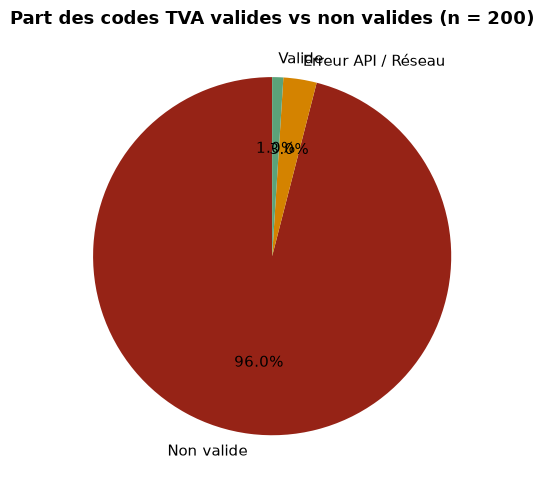

In [12]:
# création de visuels pour la directrice

import matplotlib.pyplot as plt

df_res = pd.read_csv("resultats_requetes.csv", encoding="utf-8")

def classer_reponse(texte):
  texte = str(texte)
  if texte.startswith("Valide: True"):
    return "Valide"
  elif texte.startswith("Valide: False"):
    return "Non valide"
  else:
    return "Erreur API / Réseau"

df_res["statut_tva"] = df_res["reponse"].apply(classer_reponse)

comptage = df_res["statut_tva"].value_counts()
pourcentages = df_res["statut_tva"].value_counts(normalize=True) * 100

print("=== BILAN DE LA VÉRIFICATION API VIES ===")
print(f"Total des requêtes analysées : {len(df_res)}\n")
for statut in comptage.index:
  print(f"- {statut} : {comptage[statut]} ({pourcentages[statut]:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 5))


palette = {
    "Valide": "#5ba379",
    "Non valide": "#962316", 
    "Erreur API / Réseau": "#d48300",
}
couleurs = [palette[statut] for statut in comptage.index]

ax.pie(
    comptage,
    labels=comptage.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=couleurs,
    textprops={"fontsize": 11},
)
ax.set_title(
    f"Part des codes TVA valides vs non valides (n = {len(df_res)})",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.show()